# Case Study #12 — Serang–Panimbang Toll Road: Phased Operation and the 4.68% Question
**The Feasibility Stress Test · Primary lens: Capital Budgeting**

Source: Utomo, W. & Utomo, C. (2026). *Investment Decision on the Serang–Panimbang Toll Road Project, Taking into Account the Phased Operation of the Toll Road.* Journal Research of Social Science, Economics, and Management, 5(12), 13061–13073. DOI 10.59141/jrssem.v5i12.1605 (CC BY-SA 4.0).

**Honesty disclosure.** The paper's full text was read through an automated extraction pass of the open-access PDF, not a manual page-by-page read. The paper does not publish its annual cash-flow workbook. Everything below is an **illustrative reconstruction**: an annual toll-revenue model I built from the paper's published inputs (traffic, tariff, growth, capex, opex ratio, WACC, concession), with **two calibration scalars** fitted to the paper's base NPV and capex sensitivity. Section lengths split (S1/S2), the 20-year growth window, the traffic growth beyond 2042, and the tax treatment are **my assumptions**. The reconstruction does not reproduce the paper's Monte Carlo result exactly, and the notebook says by how much.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False})
# Confirmed in the paper (IDR million unless stated)
paper = pd.DataFrame([
 ('Base-case NPV (WACC 13.55%)', 399084),
 ('Base-case IRR', '13.96%'),
 ('Discounted payback', '45 years'),
 ('Profitability index', 1.05),
 ('Total investment cost (incl. interest during construction)', 8288497),
 ('Monte Carlo mean NPV (10,000 trials, Crystal Ball)', -1203368),
 ('Monte Carlo std. deviation of NPV', 687674),
 ('Trials with NPV > 0', '468 of 10,000 (4.68%)'),
 ('Tornado: toll tariff share of variation', '33.93%'),
 ('Tornado: tariff + initial ADT S1 (cumulative)', '51.66%'),
], columns=['Item','Paper value'])
paper

,Item,Paper value
0,Base-case NPV (WACC 13.55%),399084
1,Base-case IRR,13.96%
2,Discounted payback,45 years
3,Profitability index,1.05
4,Total investment cost (incl. interest during c...,8288497
5,"Monte Carlo mean NPV (10,000 trials, Crystal B...",-1203368
6,Monte Carlo std. deviation of NPV,687674
7,Trials with NPV > 0,"468 of 10,000 (4.68%)"
8,Tornado: toll tariff share of variation,33.93%
9,Tornado: tariff + initial ADT S1 (cumulative),51.66%


## 1. The reconstruction model
Annual toll revenue per section = ADT × 365 × section length × class-mix multiplier × tariff, tariff escalated every two years at 4.67%/yr. Net operating cash flow = revenue × (1 − O&M ratio). Cash flows 2021–2069 are discounted at the paper's 13.55% WACC. Capex enters as a present value through one effective factor (PHI) back-solved from the paper's capex sensitivity; a second scalar (K) scales revenue so the base NPV lands on the paper's IDR 399,084 million.

In [2]:
WACC=0.1355; Y0=2021; END=2069
LEN={'S1':26.4,'S2':24.277,'S3':33.0}      # S3 = 33 km per paper; S1/S2 split is MY assumption (sum 50.677 km)
ADT0={'S1':8339,'S2':6442,'S3':5688}       # paper Table 12 (vehicles/day at commencement)
OPEN={'S1':2021,'S2':2023,'S3':2023}       # paper base operational years
GROW=[.12,.10,.09,.08]                     # first-years growth; then 8% (paper), within a 20-year window (MY assumption)
MULT=(6755+1.5*1084+1.5*250+2*167+2*83)/8339   # class-mix tariff multiplier from paper Table 12 (Section 1 mix)
INF=0.0467                                  # tariff indexation, applied every two years
CAPEX_LINKED=5637938*(1+0.10+0.045)        # construction + 10% VAT + 4.5% overhead (paper Table 9)
CAPEX_OTHER=7143518-CAPEX_LINKED           # other pre-financing capex (paper Table 9 subtotal)
PHI=0.655   # effective PV factor on capex, back-solved from paper's capex sensitivity (Table 17)
K=1.108     # revenue scalar so base NPV = paper's 399,084
YEARS=np.arange(Y0,END+1); DISC=(1+WACC)**-(YEARS-Y0+1)

def rev_stream(s,adt0,gscale,open_y,tariff):
    out=np.zeros(len(YEARS)); a=adt0
    for i,y in enumerate(YEARS):
        if y<open_y: continue
        k=y-open_y
        if 0<k<=20: a*=1+(GROW[k-1] if k-1<len(GROW) else .08)*gscale
        out[i]=a*365*LEN[s]*MULT*tariff*(1+INF)**(2*((y-Y0)//2))/1e6
    return out

def npv(tariff=1162,capex=1.0,opex=0.30,adt=ADT0,gscale=(1,1,1),opens=OPEN,support=0.0):
    rev=sum(rev_stream(s,adt[s],gscale[j],opens[s],tariff) for j,s in enumerate(LEN))
    return K*np.sum(rev*(1-opex)*DISC)-PHI*(CAPEX_LINKED*capex*(1-support)+CAPEX_OTHER)

base=npv(); print(f'Reconstructed base NPV: {base:,.0f}  (paper: 399,084)')

Reconstructed base NPV: 400,018  (paper: 399,084)


## 2. Validation against the paper's deterministic sensitivities (Table 17)
The capex slope was used for calibration, so only the tariff rows are out-of-sample.

In [3]:
rows=[('Toll tariff -15%',npv(tariff=1162*.85),-339228),('Toll tariff +15%',npv(tariff=1162*1.15),1132837),
      ('Construction capex +15%',npv(capex=1.15),-240700),('Construction capex -15%',npv(capex=.85),1034675)]
val=pd.DataFrame(rows,columns=['Case','Reconstruction','Paper (Table 17)']); val['Gap %']=(val['Reconstruction']/val['Paper (Table 17)']-1)*100
val.round(0)

,Case,Reconstruction,Paper (Table 17),Gap %
0,Toll tariff -15%,-361836.0,-339228,7.0
1,Toll tariff +15%,1161871.0,1132837,3.0
2,Construction capex +15%,-234229.0,-240700,-3.0
3,Construction capex -15%,1034265.0,1034675,-0.0


## 3. Monte Carlo with the paper's input distributions (Table 8)
12 inputs, independent, 10,000 trials: triangular for continuous variables (tariff 965/1,162/1,618; capex 90/100/110%; O&M ratio 20/30/40%; initial ADT per section; ADT growth 70/85/100% of base), discrete uniform for operational years (S1 2021–22, S2 2023–27, S3 2023–30).

In [4]:
def draw(n=10000,seed=42):
    r=np.random.default_rng(seed); T=r.triangular
    return dict(tariff=T(965,1162,1618,n),capex=T(.9,1,1.1,n),opex=T(.2,.3,.4,n),
      a1=T(4170,8339,10424,n),a2=T(3221,6442,8053,n),a3=T(2844,5688,7110,n),
      g1=T(.70,.85,1.0,n),g2=T(.70,.85,1.0,n),g3=T(.70,.85,1.0,n),
      o1=r.integers(2021,2023,n),o2=r.integers(2023,2028,n),o3=r.integers(2023,2031,n))
def run(d,support=0.0):
    n=len(d['tariff'])
    return np.array([npv(d['tariff'][i],d['capex'][i],d['opex'][i],{'S1':d['a1'][i],'S2':d['a2'][i],'S3':d['a3'][i]},
        (d['g1'][i],d['g2'][i],d['g3'][i]),{'S1':int(d['o1'][i]),'S2':int(d['o2'][i]),'S3':int(d['o3'][i])},support) for i in range(n)])
d=draw(); v=run(d)
res={'mean':v.mean(),'median':np.median(v),'sd':v.std(ddof=1),'min':v.min(),'max':v.max(),'p_npv_pos':(v>=0).mean()}
cmp=pd.DataFrame({'Paper (Crystal Ball)':[-1203368,-1244962,687674,-3257947,1866187,0.0468],
                  'Reconstruction (this notebook)':[res['mean'],res['median'],res['sd'],res['min'],res['max'],res['p_npv_pos']]},
                 index=['Mean NPV','Median NPV','Std dev','Min','Max','P(NPV >= 0)'])
cmp

,Paper (Crystal Ball),Reconstruction (this notebook)
Mean NPV,-1.203368e+06,-9.522972e+05
Median NPV,-1.244962e+06,-9.970960e+05
Std dev,6.876740e+05,6.869937e+05
Min,-3.257947e+06,-3.048336e+06
Max,1.866187e+06,2.098050e+06
P(NPV >= 0),4.680000e-02,8.950000e-02


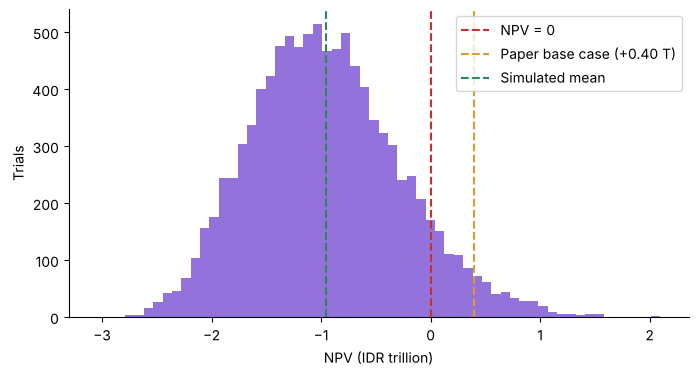

In [5]:
fig,ax=plt.subplots(); ax.hist(v/1e6,bins=60,color='#805ad5',alpha=.85)
ax.axvline(0,color='#c53030',ls='--',label='NPV = 0'); ax.axvline(399084/1e6,color='#d69e2e',ls='--',label='Paper base case (+0.40 T)')
ax.axvline(v.mean()/1e6,color='#2f855a',ls='--',label='Simulated mean')
ax.set_xlabel('NPV (IDR trillion)'); ax.set_ylabel('Trials'); ax.legend(); plt.show()

## 4. Why the simulated mean sits far below the base case
The base case uses ADT growth at 100% of plan. The paper's growth distribution is triangular 70% / **85%** / 100%, so its *most likely* value is already a 15% haircut. Setting every input to its mode (not its base) shows how much of the gap is the distribution shape alone.

In [6]:
modes_npv=npv(gscale=(.85,.85,.85)); growth_bc=run({**d,'g1':np.ones(10000),'g2':np.ones(10000),'g3':np.ones(10000)})
print(f'NPV with every input at its triangular mode (growth 85%): {modes_npv:,.0f}')
print(f'Simulated with growth fixed at plan (100%): mean {growth_bc.mean():,.0f}, P(NPV>=0) {(growth_bc>=0).mean():.1%}')

NPV with every input at its triangular mode (growth 85%): -317,631
Simulated with growth fixed at plan (100%): mean -351,184, P(NPV>=0) 30.4%


## 5. What drives the variance (rank-correlation tornado)

In [7]:
names={'tariff':'Toll tariff','a1':'Initial ADT S1','o2':'Operational year S2','opex':'O&M ratio','a2':'Initial ADT S2','capex':'Construction capex',
       'g1':'ADT growth S1','a3':'Initial ADT S3','g2':'ADT growth S2','g3':'ADT growth S3','o1':'Operational year S1','o3':'Operational year S3'}
r={k:spearmanr(d[k],v)[0]**2 for k in names}; tot=sum(r.values())
tor=pd.DataFrame({'Input':[names[k] for k in r],'Share of explained variance %':[r[k]/tot*100 for k in r]}).sort_values('Share of explained variance %',ascending=False).reset_index(drop=True)
tor['Cumulative %']=tor['Share of explained variance %'].cumsum()
paper_rank={'Toll tariff':33.93,'Initial ADT S1':51.66-33.93,'Operational year S2':62.51-51.66,'O&M ratio':72.61-62.51,'Initial ADT S2':80.93-72.61,'Construction capex':88.36-80.93}
tor['Paper %']=tor['Input'].map(lambda x: paper_rank.get(x,np.nan))
tor.round(1)

,Input,Share of explained variance %,Cumulative %,Paper %
0,Toll tariff,36.9,36.9,33.9
1,Initial ADT S1,20.8,57.8,17.7
2,O&M ratio,9.7,67.5,10.1
3,Operational year S3,7.8,75.3,NaN
4,Construction capex,6.5,81.8,7.4
5,Initial ADT S3,5.6,87.3,NaN
6,Initial ADT S2,5.4,92.8,8.3
7,Operational year S2,2.3,95.1,10.9
8,ADT growth S1,2.2,97.3,NaN
9,Operational year S1,1.0,98.3,NaN


## 6. Illustrative levers: what would have to change for the project to be a decision, not a gamble
These are **my reconstruction's** results, not the authors'. The paper recommends a tariff floor near IDR 1,068/km, regular traffic re-validation, and prioritising Section 2. It does not test government capex support or a tariff uplift, so those rows extrapolate beyond the paper.

In [8]:
n=3000; d2=draw(n,seed=7)
def P(dd,support=0.0): w=run(dd,support); return (w>=0).mean(), w.mean()
rows=[]
rows.append(('Paper input ranges (as is)',)+P(d2))
x=dict(d2); x['o2']=np.full(n,2023); rows.append(('Section 2 opens on time (2023)',)+P(x))
x=dict(d2); x['tariff']=d2['tariff']*1.2; rows.append(('Tariff distribution +20%',)+P(x))
x=dict(d2); x['tariff']=d2['tariff']*1.2; x['o2']=np.full(n,2023); rows.append(('Tariff +20% and Section 2 on time',)+P(x))
x=dict(d2); x['tariff']=d2['tariff']*1.3; rows.append(('Tariff distribution +30%',)+P(x))
rows.append(('Government funds 25% of construction-linked capex',)+P(d2,0.25))
levers=pd.DataFrame(rows,columns=['Scenario','P(NPV >= 0)','Mean NPV (IDR m)']); levers['P(NPV >= 0)']=(levers['P(NPV >= 0)']*100).round(1)
levers['Mean NPV (IDR m)']=levers['Mean NPV (IDR m)'].round(0); levers

,Scenario,P(NPV >= 0),Mean NPV (IDR m)
0,Paper input ranges (as is),9.0,-934088.0
1,Section 2 opens on time (2023),14.4,-765624.0
2,Tariff distribution +20%,38.1,-186204.0
3,Tariff +20% and Section 2 on time,48.4,15953.0
4,Tariff distribution +30%,56.3,187738.0
5,Government funds 25% of construction-linked capex,55.0,121616.0


In [9]:
out={'base_npv_reconstruction':base,'monte_carlo_10000':{k:float(x) for k,x in res.items()},
 'validation':val.round(1).to_dict('records'),'all_inputs_at_mode_npv':float(modes_npv),
 'growth_at_plan':{'mean':float(growth_bc.mean()),'p_npv_pos':float((growth_bc>=0).mean())},
 'tornado':tor.round(2).to_dict('records'),'levers':levers.to_dict('records'),
 'calibration':{'PHI':PHI,'K':K},'note':'Illustrative reconstruction; not the authors\' workbook.'}
json.dump(out,open('notebook_reconstruction_output.json','w'),indent=1,default=float); print('saved')

saved
